In [1]:
!pip install langdetect --quiet
!pip install kagglehub --quiet
!pip install seaborn --quiet
!pip install pandas --quiet
!pip install numpy --quiet
!pip install scikit-learn --quiet
!pip install nltk --quiet
!pip install emoji --quiet
!pip install --upgrade nbformat --quiet
!pip install bertopic --quiet
!pip install gensim 

2. Import Libraries
Import all dependencies required for data manipulation, NLP, and modeling.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
from transformers import AutoModel, AutoTokenizer
from collections import Counter
import os
import torch
import ssl
from gensim.models import CoherenceModel
from gensim.corpora import Dictionary
from langdetect import detect, DetectorFactory
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.tag import pos_tag
from nltk.corpus import wordnet
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from umap import UMAP
from hdbscan import HDBSCAN
import kagglehub

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Set Up Environment
Suppress unnecessary warnings and configure device settings for efficient execution.

In [3]:
os.environ["TOKENIZERS_PARALLELISM"] = "false"  
if torch.backends.mps.is_available():  # Check for Apple GPU support
    device = torch.device("mps") 
elif torch.cuda.is_available():  # Check for NVIDIA GPU support
    device = torch.device("cuda") 
else:  # Fallback to CPU
    device = torch.device("cpu")

tokenizer = AutoTokenizer.from_pretrained("vinai/bertweet-base", use_fast=True)  # Load BERTweet tokenizer
embedding_model = AutoModel.from_pretrained("vinai/bertweet-base").to(device)  # Load BERTweet model

try:  
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

warnings.filterwarnings('ignore')  # Suppress warning messages
DetectorFactory.seed = 0  # Set language detection seed for consistency
plt.style.use('default')  
sns.set_palette("husl") 

4. Download NLTK Resources & Dataset.

In [4]:
print("Ensuring required NLTK datasets are downloaded...")
nltk_downloads = [  
    'punkt', 'stopwords', 'wordnet', 'omw-1.4',
    'averaged_perceptron_tagger', 'vader_lexicon',
    'maxent_ne_chunker', 'words'
]
for dataset in nltk_downloads:  
    try:
        nltk.download(dataset, quiet=True)
    except Exception:
        pass

print("Attempting to load Formula 1 tweets dataset from KaggleHub...")
try:
    path = kagglehub.dataset_download("kaushiksuresh147/formula-1-trending-tweets")  
    files = os.listdir(path) 
    csv_files = [f for f in files if f.endswith('.csv')]
    if csv_files:
        csv_file = csv_files[0]  
        df = pd.read_csv(os.path.join(path, csv_file))
        print(f"Loaded dataset '{csv_file}' with {len(df)} rows.")
    else:
        raise Exception("No CSV files found in dataset")
except Exception:
    print("Failed to load data.")
    exit(0)

Ensuring required NLTK datasets are downloaded...
Attempting to load Formula 1 tweets dataset from KaggleHub...
Loaded dataset 'F1_tweets.csv' with 632388 rows.


5. Define Helper Functions
Utility functions are defined for POS tagging, coherence score calculation, BERTopic model initialization, Analysis and Clustering.

In [5]:
def get_wordnet_pos(word):  
    try:
        tag = pos_tag([word])[0][1][0].upper() 
        tag_dict = {"J": wordnet.ADJ, "N": wordnet.NOUN, "V": wordnet.VERB, "R": wordnet.ADV}  # Map tags to WordNet
        return tag_dict.get(tag, wordnet.NOUN)
    except Exception:
        return wordnet.NOUN

def enhanced_clean_text(text): 
    if pd.isna(text):  # Handle null values
        return ""
    text = str(text).lower()  # Convert to lowercase
    text = re.sub(r'http[s]?://\S+', '', text)  # Remove URLs
    text = re.sub(r'www\.\S+', '', text)  # Remove www links
    text = re.sub(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b', '', text)  # Remove email addresses
    f1_hashtag_pattern = r'#((?:brazil|british|dutch|hungarian|mexican|saudi|qatar|monaco|italian|spanish|french|belgian|austrian|canadian|australian|bahrain|singapore|japanese|miami|vegas|abu|dhabi)(?:gp|grandprix)?|(?:lewis|max|charles|sergio|carlos|lando|george|valtteri|fernando|daniel|esteban|lance|sebastian|kevin|mick|yuki|pierre|alex|nicholas|antonio|kimi|nikita)(?:hamilton|verstappen|leclerc|perez|sainz|norris|russell|bottas|alonso|ricciardo|ocon|stroll|vettel|magnussen|schumacher|tsunoda|gasly|albon|latifi|giovinazzi|raikkonen|mazepin)?|(?:mercedes|ferrari|redbull|mclaren|alpine|astonmartin|williams|haas|alphatauri|alfaromeo)(?:f1|racing)?)'  # F1-specific hashtag pattern
    text = re.sub(f1_hashtag_pattern, r'\1', text, flags=re.IGNORECASE)  # Extract F1 hashtag content
    text = re.sub(r'#\w+', '', text)  # Remove remaining hashtags
    text = re.sub(r'@\w+', '', text)  # Remove mentions
    text = re.sub(r'\brt\b', '', text)  # Remove retweet indicators
    text = re.sub(r'\b(?!20\d{2}\b)\d+(?:\.\d+)?\b', '', text)  # Remove numbers except years
    text = re.sub(r'[^a-zA-Z\s\.]', ' ', text)  # Keep only letters, spaces, and periods
    text = re.sub(r'\s+', ' ', text)  # Normalize whitespace
    lemmatizer = WordNetLemmatizer()  # Initialize lemmatizer
    stop_words = set(stopwords.words('english'))  # Get English stopwords
    f1_stop_words = {  # Additional F1-specific stopwords
        'get', 'go', 'come', 'see', 'look', 'watch', 'think', 'know', 'say', 'said',
        'way', 'back', 'make', 'take', 'give', 'put', 'keep', 'let', 'show', 'find',
        'work', 'try', 'use', 'want', 'need', 'like', 'love', 'hate', 'hope', 'wish',
        'today', 'tomorrow', 'yesterday', 'week', 'year', 'day', 'time', 'moment', 'now',
        'twitter', 'tweet', 'rt', 'retweet', 'follow', 'follower', 'share', 'comment'
    }
    all_stop_words = stop_words.union(f1_stop_words)  # Combine all stopwords
    try:
        tokens = word_tokenize(text)
    except Exception:
        tokens = text.split()  
    filtered_tokens = [  # Filter tokens by length and content
        token for token in tokens
        if len(token) >= 3 and len(token) <= 20 and token.lower() not in all_stop_words and not token.isdigit() and len(set(token)) > 1
    ]
    try:
        lemmatized_tokens = [lemmatizer.lemmatize(token, get_wordnet_pos(token)) for token in filtered_tokens]  # Lemmatize with POS
    except Exception:
        lemmatized_tokens = [lemmatizer.lemmatize(token) for token in filtered_tokens]  # Fallback lemmatization
    final_tokens = [token for token in lemmatized_tokens if len(token) >= 3]  # Final token filtering
    return ' '.join(final_tokens).strip()

def enhanced_quality_filter(df, text_col):  # Filter tweets for F1 relevance and quality
    f1_entities = [  # List of F1-related entities
        'verstappen', 'hamilton', 'leclerc', 'sainz', 'norris', 'russell',
        'bottas', 'perez', 'alonso', 'vettel', 'ferrari', 'mercedes',
        'redbull', 'mclaren', 'alpine', 'astonmartin', 'williams', 'haas',
        'max', 'lewis', 'charles', 'carlos', 'lando', 'george', 'valtteri',
        'sergio', 'fernando', 'sebastian', 'f1', 'formula', 'racing',
        'race', 'driver', 'team', 'season', 'championship', 'win', 'pole',
        'podium', 'pit', 'lap', 'qualifying', 'circuit', 'track'
    ]
    entity_pattern = '|'.join([re.escape(e) for e in f1_entities] + [  # Create pattern for F1 entities
    r'#f1', r'#formula1', r'#formulaone', r'#\w+gp', r'#\w+grandprix'
])
    df = df[df[text_col].str.contains(entity_pattern, case=False, na=False)].copy()  # Filter tweets containing F1 entities
    df['word_count'] = df[text_col].str.split().str.len()  # Calculate word count per tweet
    df = df[  # Apply length and word count filters
        (df['word_count'] >= 5) &
        (df['word_count'] <= 25) &
        (df[text_col].str.len() >= 30) &
        (df[text_col].str.len() <= 200)
    ].copy()
    df['text_normalized'] = df[text_col].str.lower().str.replace(r'[^a-z\s]', '', regex=True)  # Normalize text for duplicate detection
    df = df.drop_duplicates(subset=['text_normalized']).copy()  # Remove duplicate tweets
    return df

def create_model(embedding_model):  # Create BERTopic model with custom components
    umap_model = UMAP(  
        n_neighbors=8,
        n_components=15,
        min_dist=0.1,
        metric='cosine',
        random_state=42
    )
    hdbscan_model = HDBSCAN(  
        min_cluster_size=25,
        min_samples=2,
        metric='euclidean',
        cluster_selection_method='eom',
        prediction_data=True
    )
    stop_words_set = set(stopwords.words('english'))  
    f1_stop_words = {
        'get', 'go', 'come', 'see', 'look', 'watch', 'think', 'know', 'say', 'said',
        'twitter', 'tweet', 'rt', 'retweet', 'follow', 'follower', 'share', 'comment'
    }
    all_stop_words = stop_words_set.union(f1_stop_words)  
    vectorizer_model = CountVectorizer(  
        ngram_range=(1, 3),
        stop_words=list(all_stop_words),
        max_features=5000,
        min_df=2,
        max_df=0.3,
        token_pattern=r'\b[a-zA-Z]{3,}\b'
    )
    return BERTopic(
        embedding_model=embedding_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        top_n_words=12,
        nr_topics=None,
        min_topic_size=25,
        verbose=False,
        calculate_probabilities=True
    )

def clustering_approach(tweets):  # Apply topic modeling and handle outliers
    print("Fitting topic model with BERTopic...")
    topic_model = create_model(embedding_model)  # Create topic model
    topics, probabilities = topic_model.fit_transform(tweets)  # Fit model and get assignments
    print("Assigning outlier tweets to extra clusters if necessary...")
    outlier_indices = [i for i, topic in enumerate(topics) if topic == -1]  # Find outlier tweets
    if len(outlier_indices) > 50:  # Process outliers if enough exist
        if probabilities is not None:
            prob_list = []  # Extract probabilities for outliers
            for i in outlier_indices:
                p = probabilities[i]
                if isinstance(p, (int, float, np.number)):  # Handle different probability formats
                    prob_list.append(p)
                elif hasattr(p, '__len__') and len(p) > 0:
                    prob_list.append(max(p))
                else:
                    prob_list.append(0)
            prob_indices = sorted(zip(prob_list, outlier_indices), reverse=True)  # Sort by probability
            top_outliers = [idx for _, idx in prob_indices[:len(prob_indices)//2]]  # Get top outliers
            if len(top_outliers) >= 20:  # Process top outliers if enough
                print("Re-embedding top outlier tweets for mini-clustering...")
                outlier_tweets = [tweets[i] for i in top_outliers]  # Extract outlier texts
                batch = tokenizer(  # Tokenize outlier tweets
                    outlier_tweets,
                    return_tensors='pt',
                    truncation=True,
                    padding=True,
                    max_length=128
                )
                batch = {k: v.to(device) for k, v in batch.items()}  # Move to device
                with torch.no_grad():  # Generate embeddings
                    outputs = embedding_model(**batch)
                    outlier_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
                optimal_k = min(5, len(top_outliers) // 10)  # Calculate optimal cluster count
                if optimal_k >= 2:
                    kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)  # Apply KMeans clustering
                    outlier_clusters = kmeans.fit_predict(outlier_embeddings)
                    if len(set(outlier_clusters)) > 1:  # Check if clustering is meaningful
                        sil_score = silhouette_score(outlier_embeddings, outlier_clusters)  # Calculate silhouette score
                        if sil_score > 0.2:  # Apply clustering if quality is good
                            max_topic_id = max([t for t in topics if t != -1]) if any(t != -1 for t in topics) else -1  # Find max topic ID
                            for i, cluster_id in enumerate(outlier_clusters):  # Assign new topic IDs
                                topics[top_outliers[i]] = max_topic_id + 1 + cluster_id
    return topics, topic_model

def calculate_coherence(topic_model, tweets, topics, coherence_type="c_v", topn=10):  # Calculate topic coherence scores
    print(f"Calculating topic coherence scores using {coherence_type}...")
    unique_topic_ids = [t for t in set(topics) if t != -1]  # Get unique topic IDs
    topic_words = []  # Extract topic words for coherence calculation
    for topic_id in unique_topic_ids:
       topic = topic_model.get_topic(topic_id)
       if topic and isinstance(topic, list):
          words = [w for w, _ in topic[:topn] if isinstance(w, str) and " " not in w]  # Filter valid words
          if words:
              topic_words.append(words)
    tokenized_tweets = [tweet.split() for tweet in tweets]  # Tokenize tweets for coherence model
    dictionary = Dictionary(tokenized_tweets)  # Create word dictionary
    cm = CoherenceModel(  # Create coherence model
        topics=topic_words,
        texts=tokenized_tweets,
        dictionary=dictionary,
        coherence=coherence_type,
        topn=topn,
        processes=1
    )
    topic_coherences = cm.get_coherence_per_topic()  # Get per-topic coherence scores
    avg_coherence = cm.get_coherence()  # Get average coherence score
    return avg_coherence, topic_coherences

def achieve_clustering(df, text_col):  # Main clustering pipeline
    print("Filtering tweets for Formula 1 relevance and quality...")
    filtered = enhanced_quality_filter(df, text_col)  # Apply quality filters
    print(f"{len(filtered)} tweets remain after filtering.")
    if len(filtered) < 500:  # Check if enough tweets remain
        print("Not enough tweets for topic modeling after filtering.")
        return None, None, None, None, None
    print("Cleaning text for topic modeling...")
    filtered['cleaned_text'] = filtered[text_col].apply(enhanced_clean_text)  # Clean text
    filtered = filtered[filtered['cleaned_text'].str.len() > 10].copy()  # Filter by cleaned text length
    tweets_list = filtered['cleaned_text'].tolist()  # Convert to list
    print(f"Proceeding with {len(filtered)} cleaned tweets.")
    print("Starting BERTopic clustering process...")
    final_topics, topic_model = clustering_approach(tweets_list)  # Apply clustering
    avg_coherence, coherence_scores = calculate_coherence(topic_model, tweets_list, final_topics)  # type: ignore # Calculate coherence
    total_tweets = len(final_topics)
    clustered_tweets = len([t for t in final_topics if t != -1])
    num_topics = len(set(final_topics)) - (1 if -1 in final_topics else 0)
    outlier_rate = (total_tweets - clustered_tweets) / total_tweets * 100
    clustering_success_rate = (clustered_tweets / total_tweets) * 100
    print("Topic modeling complete!")
    return final_topics, topic_model, filtered, avg_coherence, coherence_scores

def get_race_name_mapping():
    return {
        'british': 'British GP', 'silverstone': 'British GP',
        'qatar': 'Qatar GP', 'losail': 'Qatar GP',
        'hungarian': 'Hungarian GP', 'hungaroring': 'Hungarian GP',
        'dutch': 'Dutch GP', 'zandvoort': 'Dutch GP',
        'saudi': 'Saudi Arabian GP', 'jeddah': 'Saudi Arabian GP',
        'abu': 'Abu Dhabi GP', 'dhabi': 'Abu Dhabi GP', 'yas': 'Abu Dhabi GP',
        'brazilian': 'Brazilian GP', 'interlagos': 'Brazilian GP', 'brazil': 'Brazilian GP',
        'monaco': 'Monaco GP', 'monte': 'Monaco GP',
        'spanish': 'Spanish GP', 'catalunya': 'Spanish GP', 'barcelona': 'Spanish GP',
        'italian': 'Italian GP', 'monza': 'Italian GP',
        'japanese': 'Japanese GP', 'suzuka': 'Japanese GP',
        'australian': 'Australian GP', 'melbourne': 'Australian GP',
        'bahrain': 'Bahrain GP', 'sakhir': 'Bahrain GP',
        'canadian': 'Canadian GP', 'montreal': 'Canadian GP',
        'austrian': 'Austrian GP', 'spielberg': 'Austrian GP',
        'french': 'French GP', 'paul': 'French GP', 'ricard': 'French GP',
        'belgian': 'Belgian GP', 'spa': 'Belgian GP',
        'miami': 'Miami GP', 'vegas': 'Las Vegas GP', 'austin': 'US GP',
        'mexican': 'Mexican GP', 'mexico': 'Mexican GP',
        'singapore': 'Singapore GP', 'marina': 'Singapore GP'
    }



6. Preprocessing and Statistics
Compute basic statistics like text length, and visualize distribution of tweet lengths.


In [6]:
text_columns = ['text', 'tweet', 'content', 'message', 'tweet_text']  # Possible text column names
text_col = None
for col in text_columns:  
    if col in df.columns:
        text_col = col
        break
if text_col is None:  
    for col in df.columns:
        if df[col].dtype == 'object':
            text_col = col
            break
if text_col is None: 
    print("No text-like column found! Exiting.")
    exit(1)

print("Preparing dataframe and sampling if required...")
df_clean = df.dropna(subset=[text_col])  # Remove null values
tweets = 45000  
if len(df_clean) > tweets:  # Sample if dataset is too large
    df_subset = df_clean.sample(tweets, random_state=42)
    print(f"Sampled {tweets} tweets from dataset for processing.")
else:
    df_subset = df_clean.copy()
    print(f"Using all {len(df_subset)} tweets for processing.")

def detect_language_safe(text):  # Safely detect text language
    try:
        if pd.isna(text) or len(str(text).strip()) < 3:
            return 'unknown'
        return detect(str(text))
    except Exception:
        return 'unknown'

print("Detecting language for each tweet...")
df_subset['language'] = df_subset[text_col].apply(detect_language_safe)  # Detect language for each tweet
lang_counts = df_subset['language'].value_counts()
english_tweets = df_subset[df_subset['language'] == 'en'].copy()  # Filter English tweets
if len(english_tweets) < 100:  # Use all tweets if not enough English ones
    print(f"Only {len(english_tweets)} English tweets detected after language filter. Using all available tweets instead.")
    english_tweets = df_subset.copy()
else:
    print(f"Found {len(english_tweets)} English tweets.")

Preparing dataframe and sampling if required...
Sampled 45000 tweets from dataset for processing.
Detecting language for each tweet...
Found 42203 English tweets.


7. Visualise Intial Statistics Plot
Visualise the distribution of Text Lengths and Distribution of Word Counts across the data.

Generating initial text statistics plots...


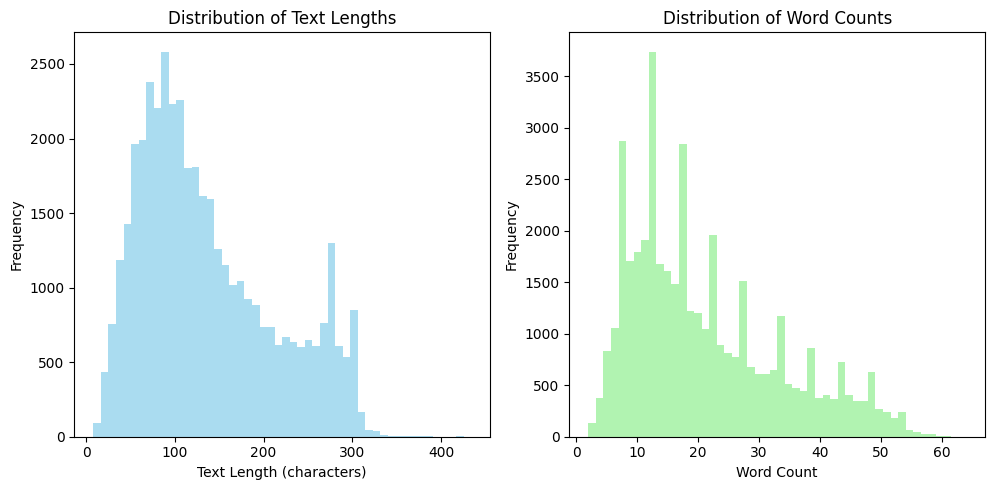

In [7]:
print("Generating initial text statistics plots...")
english_tweets['text_length'] = english_tweets[text_col].astype(str).str.len()  
english_tweets['word_count'] = english_tweets[text_col].astype(str).str.split().str.len()  
plt.figure(figsize=(15, 5))  
plt.subplot(1, 3, 1)  
plt.hist(english_tweets['text_length'], bins=50, alpha=0.7, color='skyblue')
plt.xlabel('Text Length (characters)')
plt.ylabel('Frequency')
plt.title('Distribution of Text Lengths')
plt.subplot(1, 3, 2)  
plt.hist(english_tweets['word_count'], bins=50, alpha=0.7, color='lightgreen')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.title('Distribution of Word Counts')
plt.tight_layout()
plt.show()

8. Topic Modeling with BERTopic
Train BERTopic on the dataset to extract various themes from the text.

In [8]:
print("Launching full topic modeling pipeline...")
results = achieve_clustering(english_tweets, text_col)  # Run clustering pipeline

Launching full topic modeling pipeline...
Filtering tweets for Formula 1 relevance and quality...
27766 tweets remain after filtering.
Cleaning text for topic modeling...
Proceeding with 26571 cleaned tweets.
Starting BERTopic clustering process...
Fitting topic model with BERTopic...
Assigning outlier tweets to extra clusters if necessary...
Re-embedding top outlier tweets for mini-clustering...
Calculating topic coherence scores using c_v...
Topic modeling complete!


9. EDA plots generation
Generate plots on Distribution of Text Lengths and Distribution of Word Counts for Exploratory Data Analysis.

Generating EDA plots on cleaned tweets and language breakdown...


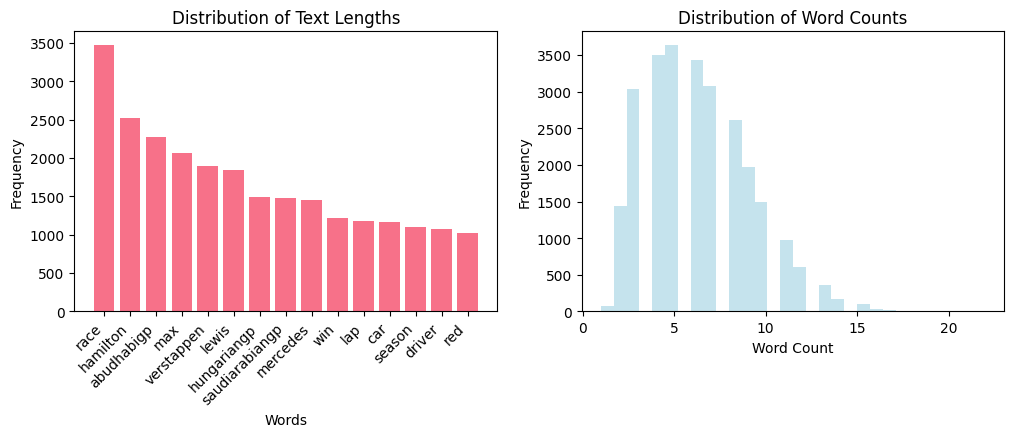

In [9]:
if results and results[0] is not None:  
    final_topics, topic_model, processed_tweets, avg_coherence, coherence_scores = results
    print("Generating EDA plots on cleaned tweets and language breakdown...")
    processed_tweets['cleaned_length'] = processed_tweets['cleaned_text'].str.len()  
    processed_tweets['cleaned_word_count'] = processed_tweets['cleaned_text'].str.split().str.len()  
    all_words = ' '.join(processed_tweets['cleaned_text']).split()  
    filtered_word_freq = Counter(all_words) 
    plt.figure(figsize=(12, 8))  
    plt.subplot(2, 2, 1)  
    top_words = dict(filtered_word_freq.most_common(15))
    plt.bar(range(len(top_words)), list(top_words.values()))
    plt.xticks(range(len(top_words)), list(top_words.keys()), rotation=45, ha='right')
    plt.xlabel('Words')
    plt.ylabel('Frequency')
    plt.title('Top 15 Most Common Words')
    plt.title('Distribution of Text Lengths')
    plt.subplot(2, 2, 2)  
    plt.hist(processed_tweets['cleaned_word_count'], bins=30, alpha=0.7, color='lightblue')
    plt.xlabel('Word Count')
    plt.ylabel('Frequency')
    plt.title('Distribution of Word Counts')

10. Visualize Topics
Generate visual summaries of topic distributions and clusters.

Plotting topic modeling results


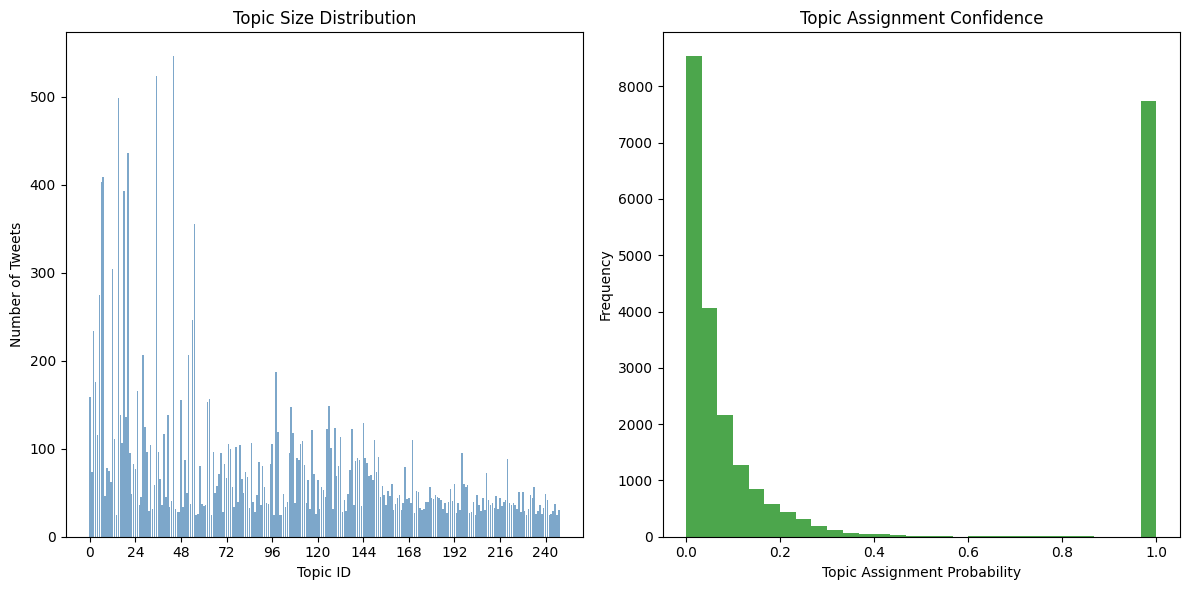

In [10]:
if results and results[0] is not None:
    print("Plotting topic modeling results")
    total_tweets = len(final_topics)
    clustered_tweets = len([t for t in final_topics if t != -1])
    clustering_success_rate = (clustered_tweets / total_tweets) * 100
    num_topics = len(set(final_topics)) - (1 if -1 in final_topics else 0)
    topic_counts = Counter(final_topics)
    plt.figure(figsize=(12, 6))  
    
    plt.subplot(1, 2, 1)  
    valid_topics = [t for t in final_topics if t != -1]
    topic_counts_valid = Counter(valid_topics)
    if topic_counts_valid:
        topic_ids = list(topic_counts_valid.keys())
        topic_sizes = list(topic_counts_valid.values())
        plt.bar(range(len(topic_ids)), topic_sizes, color='steelblue', alpha=0.7)
        plt.xlabel('Topic ID')
        plt.ylabel('Number of Tweets')
        plt.title('Topic Size Distribution')
        if len(topic_ids) <= 20:
            plt.xticks(range(len(topic_ids)), topic_ids, rotation=45)
        else:
            plt.xticks(range(0, len(topic_ids), max(1, len(topic_ids)//10)))
    
    plt.subplot(1, 2, 2)  
    probabilities = getattr(topic_model, 'probabilities_', None)
    if probabilities is not None and len(probabilities) > 0:
        if isinstance(probabilities[0], (int, float, np.number)):
            max_probs = probabilities
        else:
            max_probs = [max(prob) if hasattr(prob, '__len__') and len(prob) > 0 else
                         (prob if isinstance(prob, (int, float, np.number)) else 0)
                         for prob in probabilities]
        plt.hist(max_probs, bins=30, alpha=0.7, color='green')
        plt.xlabel('Topic Assignment Probability')
        plt.ylabel('Frequency')
        plt.title('Topic Assignment Confidence')
    
    plt.tight_layout()
    plt.show()

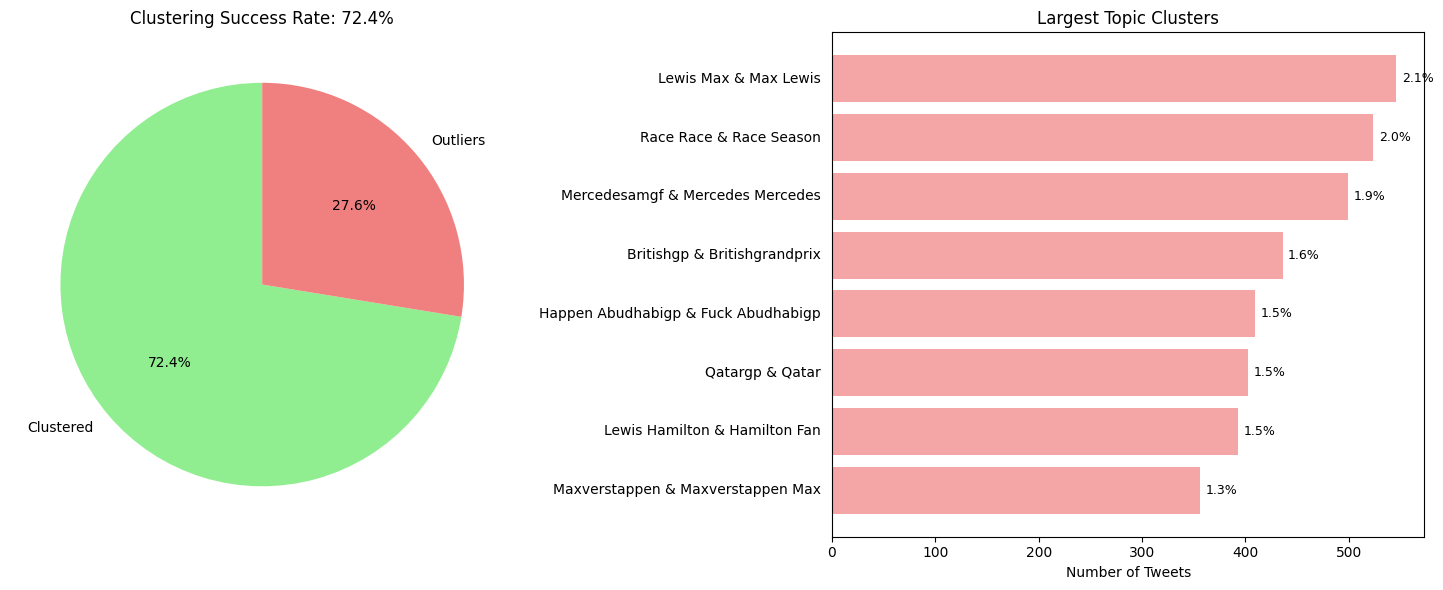

In [11]:

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)  
labels = ['Clustered', 'Outliers']
sizes = [clustering_success_rate, 100 - clustering_success_rate]
colors = ['lightgreen', 'lightcoral']
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title(f'Clustering Success Rate: {clustering_success_rate:.1f}%')

plt.subplot(1, 2, 2)  
if topic_counts_valid and topic_model:
    
    top_topics = topic_counts_valid.most_common(8)
    
    
    topic_labels = []
    topic_sizes = []
    topic_percentages = []
    
    for topic_id, count in top_topics:
        # Get topic words to create a label
        topic_words = topic_model.get_topic(topic_id)
        if topic_words:
            # Take first 2-3 most relevant words for the label
            label_words = [word for word, _ in topic_words[:2]]
            topic_label = " & ".join(label_words).title()
        else:
            topic_label = f"Topic {topic_id}"
        
        topic_labels.append(topic_label)
        topic_sizes.append(count)
        topic_percentages.append((count / total_tweets) * 100)
    
    
    y_pos = range(len(topic_labels))
    bars = plt.barh(y_pos, topic_sizes, color='lightcoral', alpha=0.7)
    
    
    for i, (bar, percentage) in enumerate(zip(bars, topic_percentages)):
        plt.text(bar.get_width() + max(topic_sizes) * 0.01, bar.get_y() + bar.get_height()/2, 
                f'{percentage:.1f}%', va='center', ha='left', fontsize=9)
    
    
    plt.yticks([])  
    for i, (bar, label) in enumerate(zip(bars, topic_labels)):
        plt.text(-max(topic_sizes) * 0.02, bar.get_y() + bar.get_height()/2, 
                label, va='center', ha='right', fontsize=10)
    
    plt.xlabel('Number of Tweets')
    plt.title('Largest Topic Clusters')
    plt.gca().invert_yaxis()  # Largest topic at the top

plt.tight_layout()
plt.show()

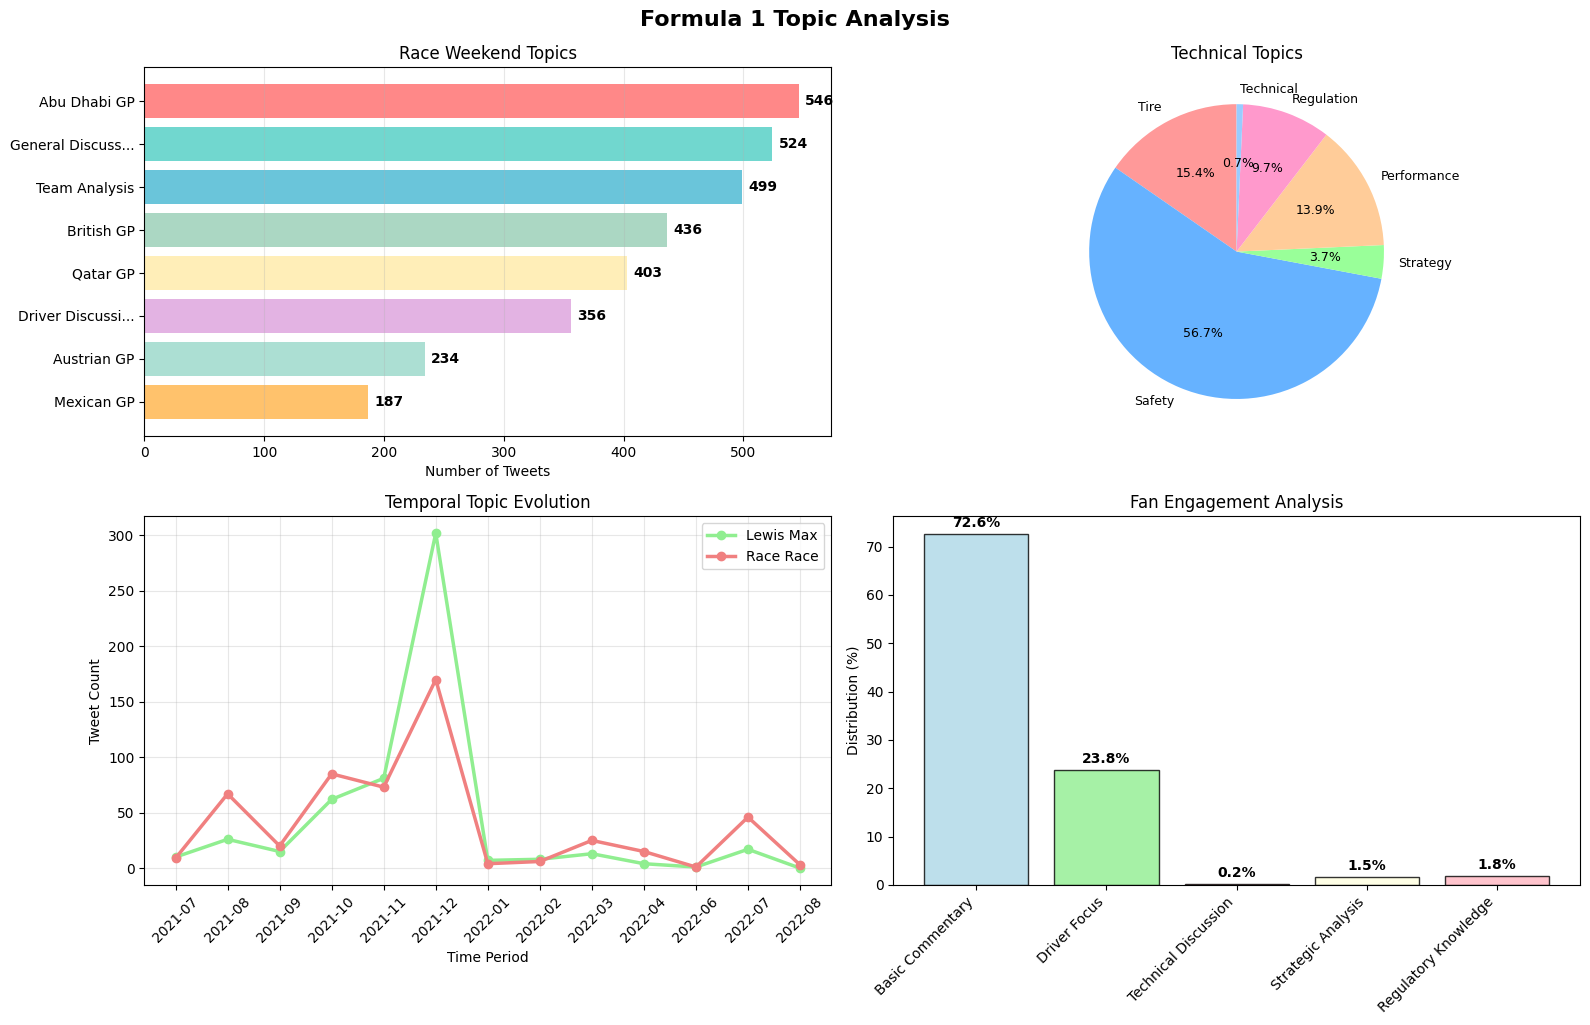

In [12]:
plt.figure(figsize=(16, 10))

race_name_mapping = get_race_name_mapping()

race_topics = []
topic_counts = Counter(final_topics)
race_indicators = ['gp', 'grand', 'prix', 'race', 'qualifying', 'practice', 'session', 'weekend']
seen_names = set()

for topic_id in set(final_topics):
    if topic_id == -1:
        continue
    words = topic_model.get_topic(topic_id)
    if not words:
        continue
    topic_text = ' '.join([w.lower() for w, _ in words[:10]])
    if 'nascar' in topic_text:
        continue
    if not any(ind in topic_text for ind in race_indicators):
        continue
    count = topic_counts.get(topic_id, 0)
    race_name = None
    best_score = 0
    for loc, full_name in race_name_mapping.items():
        if loc in topic_text:
            positions = [i for i, (w, _) in enumerate(words[:10]) if loc in w.lower()]
            if positions:
                score = sum(10 - p for p in positions)
                if score > best_score:
                    best_score = score
                    race_name = full_name
    if not race_name:
        if any(d in topic_text for d in ['hamilton', 'verstappen', 'leclerc', 'sainz', 'norris', 'russell']):
            race_name = 'Driver Discussion'
        elif any(t in topic_text for t in ['mercedes', 'ferrari', 'redbull', 'mclaren', 'alpine']):
            race_name = 'Team Analysis'
        else:
            for w, _ in words[:5]:
                cw = w.lower()
                if len(cw) > 3 and cw.isalpha() and cw not in ['race', 'grand', 'prix', 'gp', 'driver', 'team', 'discussion', 'analysis', 'nascar', 'weekend']:
                    race_name = f'{w.title()} Weekend'
                    break
            if not race_name:
                race_name = 'General Discussion'
    if race_name not in seen_names:
        race_topics.append((race_name, count, topic_id))
        seen_names.add(race_name)

race_topics.sort(key=lambda x: x[1], reverse=True)

technical_topics = []
tech_indicators = {
    'Safety': ['safety', 'car', 'yellow', 'red', 'flag'],
    'Tire': ['tire', 'tyre', 'compound', 'pit', 'strategy'],
    'Regulation': ['rule', 'regulation', 'penalty', 'steward'],
    'Technical': ['engine', 'aerodynamic', 'setup', 'downforce'],
    'Strategy': ['strategy', 'pit', 'stop', 'window'],
    'Performance': ['performance', 'lap', 'time', 'speed']
}

for topic_id in set(final_topics):
    if topic_id == -1:
        continue
    words = topic_model.get_topic(topic_id)
    if not words:
        continue
    text = ' '.join([w.lower() for w, _ in words[:10]])
    for cat, inds in tech_indicators.items():
        if any(ind in text for ind in inds):
            technical_topics.append((cat, topic_counts.get(topic_id, 0), topic_id))
            break

plt.subplot(2, 2, 1)
if race_topics:
    top_races = race_topics[:8]
    names, counts, _ = zip(*top_races)
    disp_names = [n if len(n) <= 15 else (f"{n.split()[0]} GP" if 'GP' in n else n[:15] + '...') for n in names]
    colors_geo = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7', '#DDA0DD', '#98D8C8', '#FFB347']
    bars = plt.barh(range(len(disp_names)), counts, color=colors_geo[:len(disp_names)], alpha=0.8)
    plt.xlabel('Number of Tweets')
    plt.title('Race Weekend Topics')
    plt.grid(axis='x', alpha=0.3)
    plt.yticks(range(len(disp_names)), disp_names)
    for bar, c in zip(bars, counts):
        plt.text(bar.get_width() + max(counts)*0.01, bar.get_y() + bar.get_height()/2, str(c), va='center', fontweight='bold')
    plt.gca().invert_yaxis()
else:
    plt.text(0.5, 0.5, 'No race topics detected', ha='center', va='center', transform=plt.gca().transAxes)
    plt.title('Race Weekend Topics')

plt.subplot(2, 2, 2)
if technical_topics:
    summary = {}
    for cat, cnt, _ in technical_topics:
        summary[cat] = summary.get(cat, 0) + cnt
    cats, cnts = zip(*summary.items())
    colors_tech = ['#FF9999', '#66B2FF', '#99FF99', '#FFCC99', '#FF99CC', '#99CCFF']
    plt.pie(cnts, labels=cats, colors=colors_tech[:len(cats)], autopct='%1.1f%%', startangle=90, textprops={'fontsize': 9})
    plt.title('Technical Topics')
else:
    plt.text(0.5, 0.5, 'No technical topics detected', ha='center', va='center', transform=plt.gca().transAxes)
    plt.title('Technical Topics')

plt.subplot(2, 2, 3)
temporal_drawn = False
if 'timestamp' in processed_tweets.columns or 'date' in processed_tweets.columns:
    try:
        processed_tweets['topic'] = final_topics
        processed_tweets['date_parsed'] = pd.to_datetime(processed_tweets['timestamp'] if 'timestamp' in processed_tweets.columns else processed_tweets['date'])
        span = (processed_tweets['date_parsed'].max() - processed_tweets['date_parsed'].min()).days
        if span > 365:
            processed_tweets['period'] = processed_tweets['date_parsed'].dt.to_period('M')
        elif span > 30:
            processed_tweets['period'] = processed_tweets['date_parsed'].dt.to_period('W')
        else:
            processed_tweets['period'] = processed_tweets['date_parsed'].dt.to_period('D')
        temp_data = processed_tweets.groupby(['period', 'topic']).size().unstack(fill_value=0)
        if len(temp_data) > 1:
            temporal_drawn = True
            periods = [str(p) for p in temp_data.index]
            top_topics = temp_data.sum().nlargest(3)
            colors_tmp = ['steelblue', 'lightgreen', 'lightcoral']
            for i, (tid, _) in enumerate(top_topics.items()):
                if tid == -1:
                    continue
                label = topic_model.get_topic(tid)[0][0].title() if topic_model.get_topic(tid) else f'Topic {tid}'
                plt.plot(periods, temp_data[tid], marker='o', linewidth=2.5, label=label, color=colors_tmp[i])
            plt.xlabel('Time Period')
            plt.ylabel('Tweet Count')
            plt.title('Temporal Topic Evolution')
            plt.legend()
            plt.xticks(rotation=45)
            plt.grid(alpha=0.3)
    except Exception:
        temporal_drawn = False
if not temporal_drawn:
    plt.text(0.5, 0.5, 'No temporal data available', ha='center', va='center', transform=plt.gca().transAxes)
    plt.title('Temporal Topic Evolution')

plt.subplot(2, 2, 4)
engagement = {'Basic Commentary': 0, 'Driver Focus': 0, 'Technical Discussion': 0, 'Strategic Analysis': 0, 'Regulatory Knowledge': 0}
for topic_id in set(final_topics):
    if topic_id == -1:
        continue
    words = topic_model.get_topic(topic_id)
    if not words:
        continue
    text = ' '.join([w.lower() for w, _ in words[:8]])
    count = topic_counts.get(topic_id, 0)
    if any(x in text for x in ['hamilton', 'verstappen', 'leclerc', 'sainz', 'norris', 'russell']):
        engagement['Driver Focus'] += count
    elif any(x in text for x in ['engine', 'aerodynamic', 'setup', 'technical', 'engineering']):
        engagement['Technical Discussion'] += count
    elif any(x in text for x in ['strategy', 'pit', 'window', 'tactical', 'decision']):
        engagement['Strategic Analysis'] += count
    elif any(x in text for x in ['rule', 'regulation', 'penalty', 'steward']):
        engagement['Regulatory Knowledge'] += count
    else:
        engagement['Basic Commentary'] += count
total = sum(engagement.values())
if total > 0:
    for k in engagement:
        engagement[k] = engagement[k] / total * 100
cats, vals = list(engagement.keys()), list(engagement.values())
if sum(vals) > 0:
    colors_eng = ['lightblue', 'lightgreen', 'lightcoral', 'lightyellow', 'lightpink']
    bars = plt.bar(cats, vals, color=colors_eng, alpha=0.8, edgecolor='black', linewidth=1)
    plt.ylabel('Distribution (%)')
    plt.title('Fan Engagement Analysis')
    plt.xticks(rotation=45, ha='right')
    for i, v in enumerate(vals):
        plt.text(i, v + max(vals)*0.02, f'{v:.1f}%', ha='center', fontweight='bold')
else:
    plt.text(0.5, 0.5, 'No engagement data available', ha='center', va='center', transform=plt.gca().transAxes)
    plt.title('Fan Engagement Analysis')

plt.tight_layout()
plt.suptitle('Formula 1 Topic Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.show()

11. Visualise Evaluatation Metrics
Visualise the total tweets classified by the model and its success rate.

Evaluation metrics and additional plots...


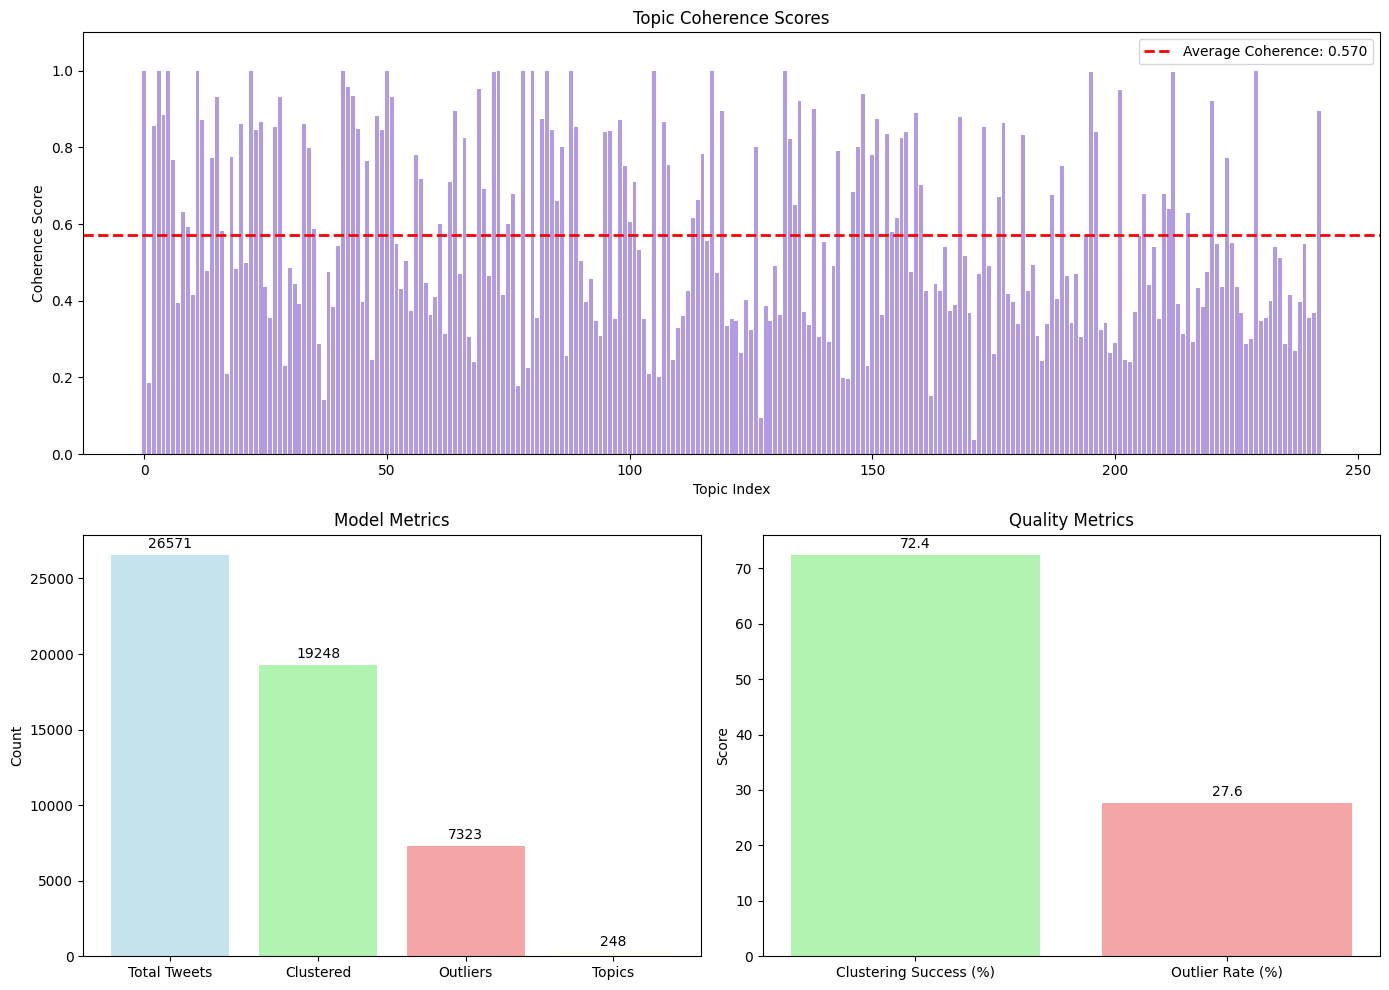

In [13]:
if results and results[0] is not None:    
    print("Evaluation metrics and additional plots...")
    plt.figure(figsize=(14, 10))  
    
    # Topic coherence scores (top, spanning full width)
    plt.subplot(2, 2, (1, 2))  
    if coherence_scores and len(coherence_scores) > 0:
        topic_ids = list(range(len(coherence_scores)))
        bars = plt.bar(topic_ids, coherence_scores, color='mediumpurple', alpha=0.7)
        plt.axhline(y=avg_coherence, color='red', linestyle='--', linewidth=2, 
                    label=f'Average Coherence: {avg_coherence:.3f}')
        plt.xlabel('Topic Index')
        plt.ylabel('Coherence Score')
        plt.title('Topic Coherence Scores')
        plt.legend()
        plt.ylim(0, max(coherence_scores) * 1.1)

    else:
        plt.text(0.5, 0.5, 'Coherence scores not available', 
                 ha='center', va='center', transform=plt.gca().transAxes)
        plt.title('Topic Coherence Scores')
    # Model metrics bar chart (bottom left)
    plt.subplot(2, 2, 3)
    metrics = ['Total Tweets', 'Clustered', 'Outliers', 'Topics']
    values = [total_tweets, clustered_tweets, topic_counts.get(-1, 0), num_topics]
    colors = ['lightblue', 'lightgreen', 'lightcoral', 'lightyellow']
    bars = plt.bar(metrics, values, color=colors, alpha=0.7)
    plt.title('Model Metrics')
    plt.ylabel('Count')
    for i, v in enumerate(values): 
        plt.text(i, v + max(values)*0.01, str(v), ha='center', va='bottom')
    
    # Quality metrics (bottom right)
    plt.subplot(2, 2, 4)
    success_metrics = ['Clustering Success (%)', 'Outlier Rate (%)']
    success_values = [clustering_success_rate, (100 - clustering_success_rate)]
    bars = plt.bar(success_metrics, success_values, color=['lightgreen', 'lightcoral'], alpha=0.7)
    plt.title('Quality Metrics')
    plt.ylabel('Score')
    for i, v in enumerate(success_values): 
        plt.text(i, v + max(success_values)*0.01, f'{v:.1f}', ha='center', va='bottom')
    
    plt.tight_layout()
    plt.show()


12. Interactive Intertopic Distance Map Generation
Generate an intertopic distance map to display the relationships between different topics

In [14]:
topic_model.visualize_topics()

13. Summary
This notebook successfully applies BERTopic to extract meaningful topics from tweets. Results are then visualized and evaluated using coherence scores and keyword relevance. 

In [15]:
topic_counts = Counter(final_topics)
unique_topic_ids = sorted([t for t in set(final_topics) if t != -1])  # Get sorted topic IDs

print("TOPIC MODELING RESULTS")
print("=" * 50)
print("Total tweets: {}".format(total_tweets))
clustered_tweets = len([t for t in final_topics if t != -1])  # Count clustered tweets
print("Clustered: {}".format(clustered_tweets))
print("Success rate: {:.2f}%".format((clustered_tweets / total_tweets) * 100 if total_tweets else 0))
print("Topics found: {}".format(len(unique_topic_ids)))
print("Outliers: {} ({:.1f}%)".format(topic_counts.get(-1, 0), (topic_counts.get(-1, 0) / total_tweets) * 100 if total_tweets else 0))
print("Coherence Score: {:.4f}".format(avg_coherence))
print("\n" + "=" * 50)
print("DETAILED TOPIC BREAKDOWN")
print("=" * 50)

for idx, topic_id in enumerate(unique_topic_ids):  # Write details for each topic
    count = topic_counts.get(topic_id, 0)
    try:
        topic_words = topic_model.get_topic(topic_id)  
        words_str = ", ".join([word for word, _ in topic_words[:12]]) if topic_words else ""
        percentage = (count / total_tweets) * 100
        print(f"\nTOPIC {topic_id} (#{idx + 1}, {count} tweets, {percentage:.1f}%):")
        print(f" Words: {words_str}")
        if coherence_scores and idx < len(coherence_scores):  
            print(f" Coherence: {coherence_scores[idx]:.4f}")
    except Exception:
        continue


TOPIC MODELING RESULTS
Total tweets: 26571
Clustered: 19248
Success rate: 72.44%
Topics found: 248
Outliers: 7323 (27.6%)
Coherence Score: 0.5702

DETAILED TOPIC BREAKDOWN

TOPIC 0 (#1, 546 tweets, 2.1%):
 Words: lewis max, max lewis, lewis abudhabigp, lewis lewis, abudhabigp lewis, lewis win, lewis robbed, lewis fan, race lewis, robbed, max fan, amp lewis
 Coherence: 1.0000

TOPIC 1 (#2, 524 tweets, 2.0%):
 Words: race race, race season, race weekend, race one, final race, great race, best race, last race, excite race, season race, start race, next race
 Coherence: 0.1843

TOPIC 2 (#3, 499 tweets, 1.9%):
 Words: mercedesamgf, mercedes mercedes, mercedesgp, mercedesamgf mercedes, amg, mercedes amg, mercedes team, porpoising, mercedesgp mercedes, suspension, court, mercedes strategy
 Coherence: 0.8568

TOPIC 3 (#4, 436 tweets, 1.6%):
 Words: britishgp, britishgrandprix, race britishgp, britishgp race, britishgp britishgp, british, best race, britishgrandprix britishgp, britishgp ocon, b